Code by: Tommaso Pintonato 2069337

In [1]:
!git clone https://github.com/Tzomy/PizzaCurta_VI
!pip install pymap3d

Cloning into 'PizzaCurta_VI'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), 8.81 KiB | 8.81 MiB/s, done.


Importiamo tutte le librerie necessarie

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
from itertools import combinations

Carichiamo il dataset all'interno del programma

In [3]:
df = pd.read_csv('PizzaCurta_VI/Pizzeria_VI_dati.csv')

In [4]:
df.head()

,Quartieri,Costo affitto,Latitudine,Longitudine
0,Centro Storico,4500,45.548711,11.545559
1,Borgo Berga Stadio,2000,45.545167,11.554290
2,San Francesco Parco Città,1000,45.557310,11.564017
3,Saviabona,700,45.566123,11.557984
4,Anconetta Ospedaletto,700,45.570492,11.573629


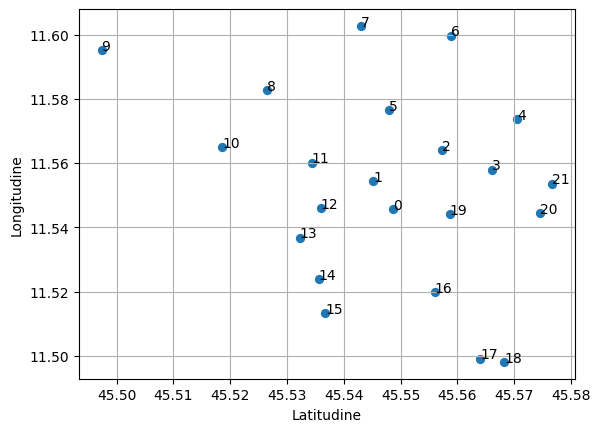

<Figure size 800x640 with 0 Axes>

In [5]:
for i in range(len(df)):
  plt.annotate(i, (df['Latitudine'][i], df['Longitudine'][i]))

plt.scatter(df['Latitudine'], df['Longitudine'], s=32)
plt.xlabel('Latitudine')
plt.ylabel('Longitudine')
plt.grid(True)
plt.figure(figsize=(10, 8), dpi=80)
plt.show()

Vediamo come sono posizionati i vari punti sulla mappa

Trasformiamo le informazioni di latitudine e longitudine in dati maggiormente utili quali le lunghezze in metri.  
Similarly, the length in meters of a degree of longitude can be calculated as:

> On the WGS 84 spheroid, the length in meters of a degree of latitude at latitude $\phi$ (that is, the number of meters you would have to travel along a north–south line to move 1 degree in latitude, when at latitude $\phi$), is about:  

$$\displaystyle 111132.92-559.82\,\cos 2\phi +1.175\,\cos 4\phi -0.0023\,\cos 6\phi $$  
> The returned measure of meters per degree latitude varies continuously with latitude.  
Similarly, the length in meters of a degree of longitude can be calculated as:

$$\displaystyle 111412.84\,\cos \phi -93.5\,\cos 3\phi +0.118\,\cos 5\phi $$
[From wikipedia](https://en.wikipedia.org/wiki/Geographic_coordinate_system#:~:text=On%20the%20WGS,be%20calculated%20as)

In [6]:
def Lenght_lat(latitude):
  return 111132.92 - 559.82 * math.cos(2 * latitude) + 1.175 * math.cos(4 * latitude) - 0.0023 * math.cos(6 * latitude)

def Lenght_lon(longitude):
  return 111412.84 * math.cos(longitude) - 93.5 * math.cos(3 * longitude) + 0.118 * math.cos(5 * longitude)

In [7]:
print(Lenght_lat(math.pi/4)) #Restituisce la lunghezza in metri di un grado di latitudine
print(Lenght_lon(math.pi/4)) #Restituisce la lunghezza in metri di un grado di longitudine

111131.745
78846.80572069259


Queste sono delle lunghezze di latitudine e longitudine per degli angoli standard i quali risultano corretti secondo la tabella indicata su [wikipedia ](https://en.wikipedia.org/wiki/Latitude#:~:text=45%C2%B0,78.847%C2%A0km)

In [8]:
min_lat = df['Latitudine'].min()
min_lon = df['Longitudine'].min()

In [9]:
Lat_radians = [0 for _ in range(len(df))]
Lon_radians = [0 for _ in range(len(df))]
for i in range(len(df)):
  Lat_radians[i] = ((df['Latitudine'][i]) * math.pi/180) #trasformiamo gli angoli da gradi a radianti per il calcolo delle coordinate
  Lon_radians[i] = ((df['Longitudine'][i]) * math.pi/180)

In [10]:
print(Lat_radians)
print(Lon_radians)

[np.float64(0.7949749836216101), np.float64(0.7949131261858596), np.float64(0.795125062389594), np.float64(0.7952788810490989), np.float64(0.7953551301207955), np.float64(0.7949614946699531), np.float64(0.7951510758239633), np.float64(0.7948759984948137), np.float64(0.794587245987376), np.float64(0.7940788905683988), np.float64(0.7944499545486896), np.float64(0.7947240187142084), np.float64(0.7947526738789336), np.float64(0.7946880382280799), np.float64(0.7947460550668113), np.float64(0.794766089352229), np.float64(0.7951019730798535), np.float64(0.7952427815315153), np.float64(0.7953166028502224), np.float64(0.7951488583831485), np.float64(0.7954258660464507), np.float64(0.795464376736396)]
[np.float64(0.20150801591527012), np.float64(0.2016604044519861), np.float64(0.2018301757699202), np.float64(0.20172487813628526), np.float64(0.20199794030828044), np.float64(0.2020459146970288), np.float64(0.20245238320479528), np.float64(0.2025049364648362), np.float64(0.20215633173042574), np.fl

In [11]:
df.insert(4, "Lat_radians", Lat_radians)
df.insert(5, "Lon_radians", Lon_radians)

In [12]:
X_meters = [0 for _ in range(len(df))]
Y_meters = [0 for _ in range(len(df))]
for i in range(len(df)):
  X_meters[i] = (df['Longitudine'][i] - min_lon) * Lenght_lon(df['Longitudine'][i])
  Y_meters[i] = (df['Latitudine'][i]- min_lat) * Lenght_lat(df['Latitudine'][i])

In [13]:
df.insert(6, "X_meters", X_meters)
df.insert(7, "Y_meters", Y_meters)

In [14]:
df

,Quartieri,Costo affitto,Latitudine,Longitudine,Lat_radians,Lon_radians,X_meters,Y_meters
0,Centro Storico,4500,45.548711,11.545559,0.794975,0.201508,2768.805307,5734.627082
1,Borgo Berga Stadio,2000,45.545167,11.554290,0.794913,0.201660,3324.532669,5338.762574
2,San Francesco Parco Città,1000,45.557310,11.564017,0.795125,0.201830,3960.299935,6695.069583
3,Saviabona,700,45.566123,11.557984,0.795279,0.201725,3563.918626,7679.433972
4,Anconetta Ospedaletto,700,45.570492,11.573629,0.795355,0.201998,4605.626754,8167.384962
5,San Pio X,600,45.547939,11.576378,0.794961,0.202046,4793.263202,5648.302917
6,Bertesina,500,45.558801,11.599667,0.795151,0.202452,6437.610165,6861.543843
7,Bertesinella,600,45.543040,11.602678,0.794876,0.202505,6657.263243,5101.158750
8,Casale,700,45.526496,11.582705,0.794587,0.202156,5230.323052,3253.243026
9,San Pietro Intrigogna,500,45.497369,11.595236,0.794079,0.202375,6117.316510,0.000000


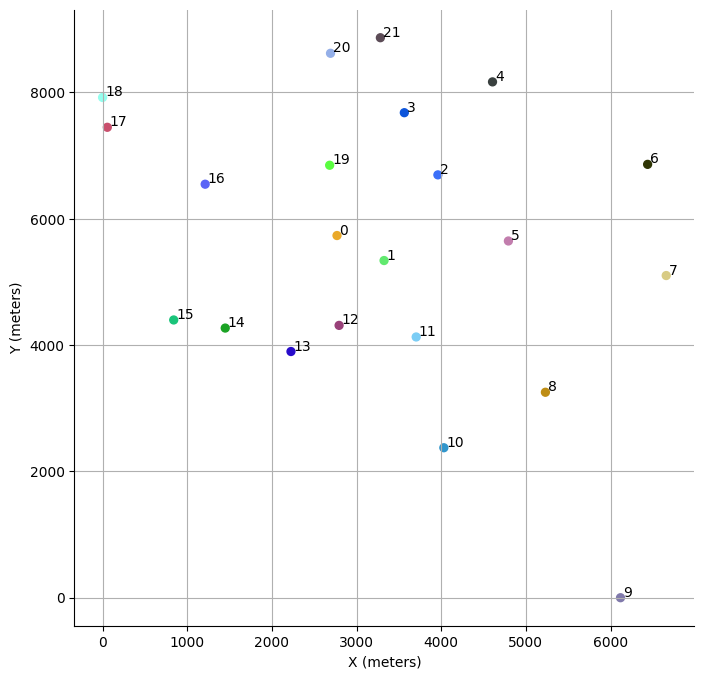

In [15]:
fig, ax = plt.subplots()

fig.set_size_inches(8, 8)
ax.scatter(df['X_meters'], df['Y_meters'], s=32, c=np.random.rand(len(df), 3))


ax.set_xlabel('X (meters)')
ax.set_ylabel('Y (meters)')
plt.grid(True)

for i in range(len(df)):
  plt.annotate(i, (df['X_meters'][i] + 30, df['Y_meters'][i] + 20))


plt.gca().spines[['top', 'right']].set_visible(False)


plt.show()

Abbiamo quindi scalato il grafico tenendo conto delle distanze reali esprimendole in metri  



Come possiamo vedere nonostante le poroporzioni sono state rispettate i grafici non coincidono con il grafico fornito per il problema  
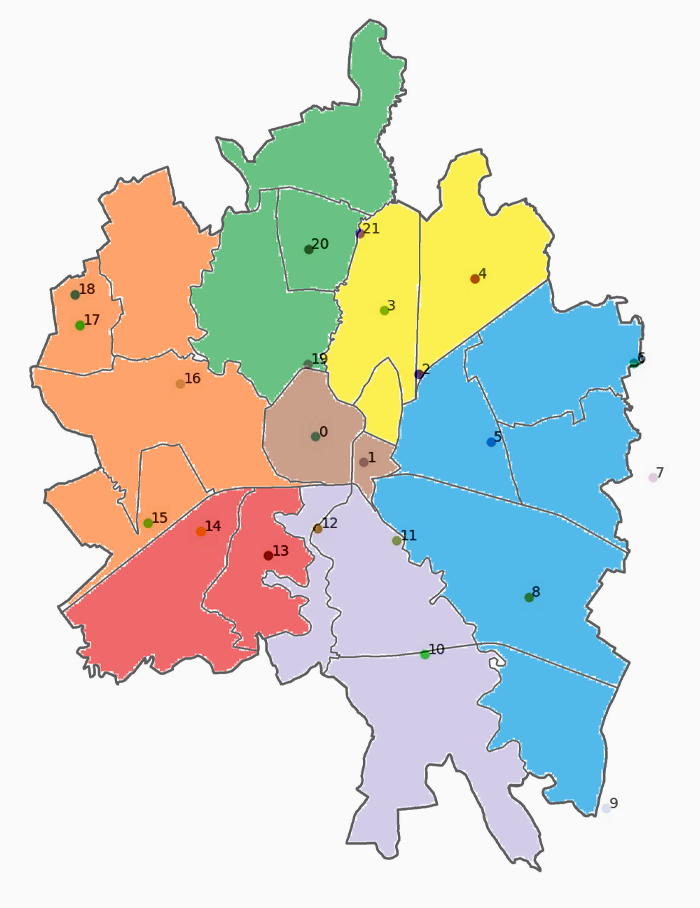  
Ho cercato l'immagine originale poichè quella fornita dal problema era stata scalata, nonostante ciò le coordiante non sembrano precise.

In [16]:
from geopy import distance
for i in range(len(df)):
  dist_origine = distance.distance((min_lat, min_lon), (df['Latitudine'][i], df['Longitudine'][i]))
  print(math.sqrt( math.pow(df['X_meters'][i], 2) + math.pow(df['Y_meters'][i], 2) ))
  print(dist_origine.m)
  print("\n")


6368.063331418287
6805.630425347892


6289.268898958888
6892.208480331158


7778.684483476141
8420.761439484126


8466.122022111671
8960.11146066328


9376.458548611541
10043.25776025156


7408.015791320093
8306.714317856917


9408.698557540358
10468.331142673742


8386.952633548044
9619.856272157793


6159.534837170671
7362.02108108793


6117.316510385266
7593.324637912868


4678.022913914087
5743.481253928242


5546.583009078103
6354.232821547779


5137.71230340815
5691.7152219176005


4488.581888728281
4918.5479887577385


4508.604008286723
4700.887943123771


4477.320020764364
4534.600997767989


6658.479766171219
6731.735835836905


7448.625494288023
7412.072751966216


7920.832737621935
7881.7251084335385


7353.851567187606
7706.215237634929


9030.639145687197
9307.128805591912


9454.07716341315
9831.091836041216




Vediamo che la formula restituisce per la distanza dei punti valori errati rispetto a quelli calcolati tramite la libreria

Proviamo quindi ad adoperare un'altra libreria per calcolare le coordinate

In [17]:
import pymap3d as pm
X_coord = np.zeros(shape=(len(df),1))
Y_coord = np.zeros(shape=(len(df),1))
for i in range(len(df)):
  lat = df['Latitudine'][i]
  lon = df['Longitudine'][i]
  point = pm.enu.geodetic2enu(lat, lon, 39, min_lat, min_lon, 39)
  X_coord[i] = point[0]
  Y_coord[i] = point[1]

In [18]:
df.insert(len(df.columns), "X_coord", X_coord)
df.insert(len(df.columns), "Y_coord", Y_coord)

In [19]:
df

,Quartieri,Costo affitto,Latitudine,Longitudine,Lat_radians,Lon_radians,X_meters,Y_meters,X_coord,Y_coord
0,Centro Storico,4500,45.548711,11.545559,0.794975,0.201508,2768.805307,5734.627082,3.707088e+03,5707.420898
1,Borgo Berga Stadio,2000,45.545167,11.554290,0.794913,0.201660,3324.532669,5338.762574,4.389194e+03,5313.950898
2,San Francesco Parco Città,1000,45.557310,11.564017,0.795125,0.201830,3960.299935,6695.069583,5.147739e+03,6664.145104
3,Saviabona,700,45.566123,11.557984,0.795279,0.201725,3563.918626,7679.433972,4.675948e+03,7643.300185
4,Anconetta Ospedaletto,700,45.570492,11.573629,0.795355,0.201998,4605.626754,8167.384962,5.896872e+03,8129.887632
5,San Pio X,600,45.547939,11.576378,0.794961,0.202046,4793.263202,5648.302917,6.113886e+03,5623.406699
6,Bertesina,500,45.558801,11.599667,0.795151,0.202452,6437.610165,6861.543843,7.931039e+03,6832.701646
7,Bertesinella,600,45.543040,11.602678,0.794876,0.202505,6657.263243,5101.158750,8.168418e+03,5081.302781
8,Casale,700,45.526496,11.582705,0.794587,0.202156,5230.323052,3253.243026,6.610442e+03,3240.685571
9,San Pietro Intrigogna,500,45.497369,11.595236,0.794079,0.202375,6117.316510,0.000000,7.593368e+03,4.591371


In [20]:
"""
for i in range(len(df)):
  dist_origine = distance.distance((min_lat, min_lon), (df['Latitudine'][i], df['Longitudine'][i]))
  print(math.sqrt( math.pow(df['X_coord'][i], 2) + math.pow(df['Y_coord'][i], 2) ))
  print(dist_origine.m)
  print("\n")
"""

'\nfor i in range(len(df)):\n  dist_origine = distance.distance((min_lat, min_lon), (df[\'Latitudine\'][i], df[\'Longitudine\'][i]))\n  print(math.sqrt( math.pow(df[\'X_coord\'][i], 2) + math.pow(df[\'Y_coord\'][i], 2) ))\n  print(dist_origine.m)\n  print("\n")\n'

Adoperando questa libreria i dati sono corretti per cui possiamo andare ad adoperarli, per comodità ho adoperato il sistema di coordinate ENU (East Nord Up)
[sistemi di coordinate](https://dirsig.cis.rit.edu/docs/new/coordinates.html#_positioning_scene_elements)

Per cui andiamo a rimuovere le coordinate non necessarie alla risoluzione del problema quali:
- Valori in randianti degli angoli
- Vecchie coordinate errate

In [21]:
df = df.drop(['Lat_radians', 'Lon_radians', 'X_meters', 'Y_meters'], axis=1)

Ora il dataframe è corretto e possiamo proseguire con la risoluzione del problema.  
La piantina reale risulta comunque fuori scala rispetto ai dati che sono stati trovati

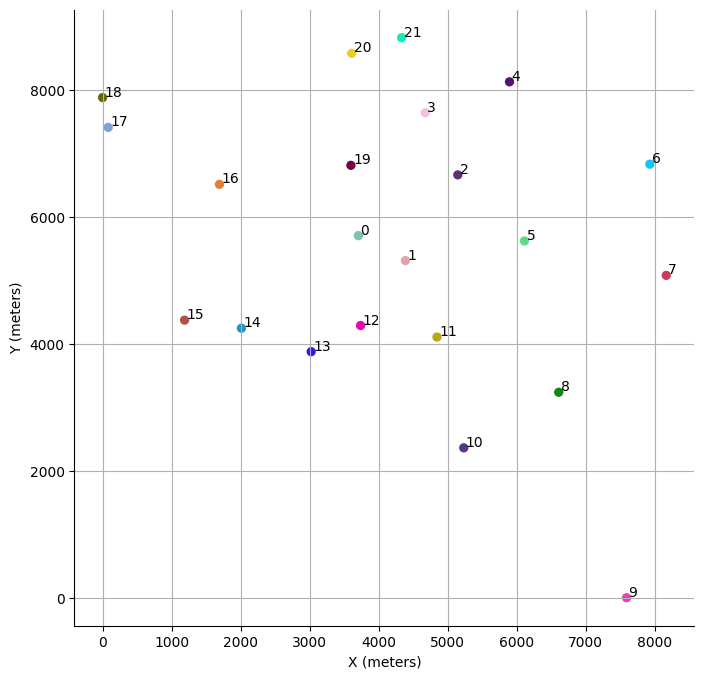

In [22]:
fig, ax = plt.subplots()

fig.set_size_inches(8, 8)
ax.scatter(df['X_coord'], df['Y_coord'], s=32, c=np.random.rand(len(df), 3))


ax.set_xlabel('X (meters)')
ax.set_ylabel('Y (meters)')
plt.grid(True)

for i in range(len(df)):
  plt.annotate(i, (df['X_coord'][i] + 30, df['Y_coord'][i] + 20))


plt.gca().spines[['top', 'right']].set_visible(False)


plt.show()

Proseguiamo dunque con la programmazione di un risolutore partendo dal calcolare la distanza che può percorrere un cliente nel nostro modello.  
Sappiamo che le distanze vegnono percorse alla velocità di 20 km/h mediamente e le varie sedi della pizzeria devono essere raggiungibili entro 5 minuti. Per cui sappiamo che la pizzeria deve essere entro un raggio di $\dfrac{20}{3,6} \cdot 5 \cdot 60$ metri perchè sia effettivamente raggiungibile dalle persone

In [23]:
R = 20 / 3.6 * 5 * 60

Per cui troviamo che la pizzeria riesce ad essere disponibile entro un raggio di $1,666 \text{ km}$

Possiamo quindi andare a graficare questo raggio sulle varie pizzerie per ragionare un attimo sul problema

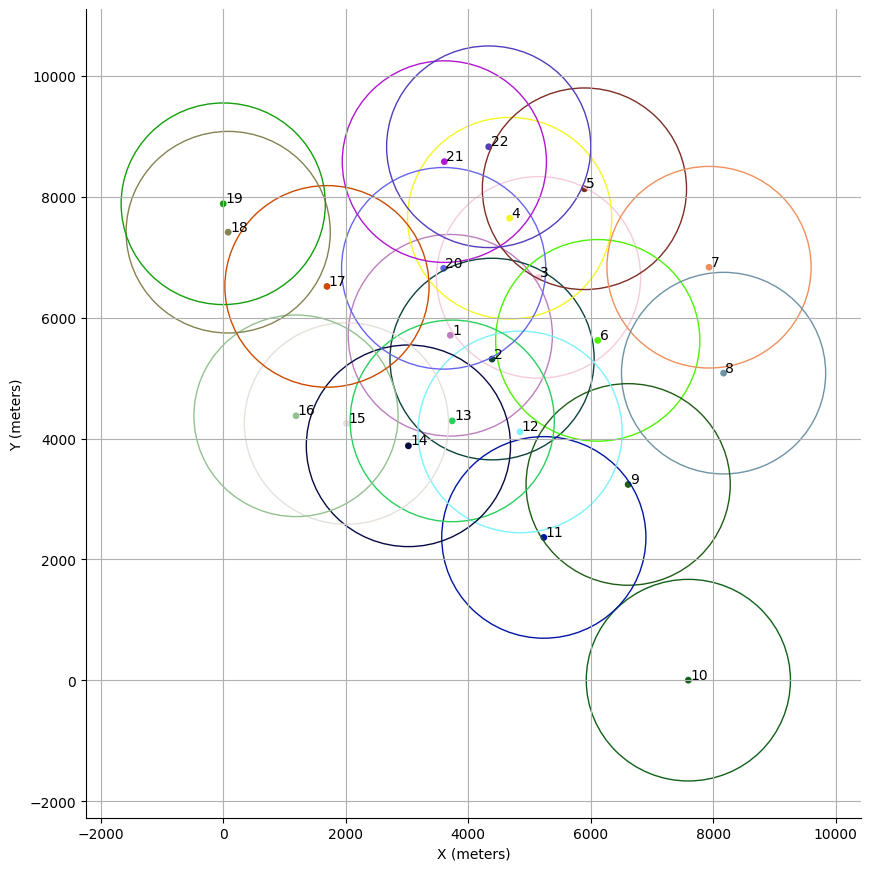

In [24]:
fig, ax = plt.subplots()

rand_color = np.random.rand(len(df), 3)
fig.set_size_inches(10, 10.5)
ax.scatter(df['X_coord'], df['Y_coord'], s=15, c=rand_color)


ax.set_xlabel('X (meters)')
ax.set_ylabel('Y (meters)')
plt.grid(True)

for i in range(len(df)):
  plt.annotate(i + 1, (df['X_coord'][i] + 30, df['Y_coord'][i] + 20))
  circle = plt.Circle((df['X_coord'][i], df['Y_coord'][i]), R, color=rand_color[i], fill=False)
  ax.add_patch(circle)


plt.gca().spines[['top', 'right']].set_visible(False)


plt.show()

Possiamo vedere ad occhio che ci sono dei centri "indipendenti", tali punti possiamo definirli come indipendenti perchè presentano solamente un altra pizzeria all'interno della circonferenza la quale non contiene ulteriori pizzerie al suo interno.  
Ma ne troviamo anche di accoppiate tra loro per cui rappresentano una coppia indipendente  

Tali punti sono:
- $6, 7, 9, 16$ completamente indipendenti  

- $(8, 10)$ e $(17, 18)$ coppie escluse dal resto delle zone  

Per cui possiamo andare ad escludere i punti $6, 7, 9, 16$ poichè per riuscire a fornire il servizio entro 5 minuti non abbiamo altre alternative

In [25]:
pizzerias_1 = np.array([6, 7, 9, 16]) #pizzerie singole

Mentre per quelle doppie andremo semplicemente a scegliere la locazione meno costosa delle due

In [26]:
pizzerias_2 = np.array([8, 10, 17, 18]) #pizzerie doppie

Calcolaimo quale sia la pizzeria da tenere di quelle doppie

In [27]:
pizzerias = []
for i in range(0, 4, 2):
  if (df['Costo affitto'][pizzerias_2[i]] > df['Costo affitto'][pizzerias_2[i+1]]):
    pizzerias = np.append(pizzerias, pizzerias_2[i + 1])
  else: pizzerias = np.append(pizzerias, pizzerias_2[i])

Ed eliminiamo le pizzerie indipendenti dalle altre dal dataset per velocizzare i calcoli successivi

In [28]:
pizzerias_considered = np.concatenate((pizzerias_1, pizzerias_2), dtype=int) #queste pizzerie sicuramente sono da considerare nella soluzione

In [29]:
df_updated = df.drop(pizzerias_considered)

Salviamo allora gli indici delle pizzerie che rimangono da tenere in considerazione

In [30]:
index = df_updated.index

In [31]:
index

Index([0, 1, 2, 3, 4, 5, 11, 12, 13, 14, 15, 19, 20, 21], dtype='int64')

In [32]:
df_updated

,Quartieri,Costo affitto,Latitudine,Longitudine,X_coord,Y_coord
0,Centro Storico,4500,45.548711,11.545559,3707.087988,5707.420898
1,Borgo Berga Stadio,2000,45.545167,11.554290,4389.194250,5313.950898
2,San Francesco Parco Città,1000,45.557310,11.564017,5147.739262,6664.145104
3,Saviabona,700,45.566123,11.557984,4675.947956,7643.300185
4,Anconetta Ospedaletto,700,45.570492,11.573629,5896.872407,8129.887632
5,San Pio X,600,45.547939,11.576378,6113.886206,5623.406699
11,Campedello,400,45.534332,11.560128,4846.057880,4110.045990
12,Monte Berico,3000,45.535974,11.545951,3738.550839,4291.765072
13,Gogna,600,45.532271,11.536790,3023.197521,3879.778631
14,Ferrovieri,800,45.535595,11.523840,2011.491932,4248.825034


Visualizziamo quindi le pizzerie restanti

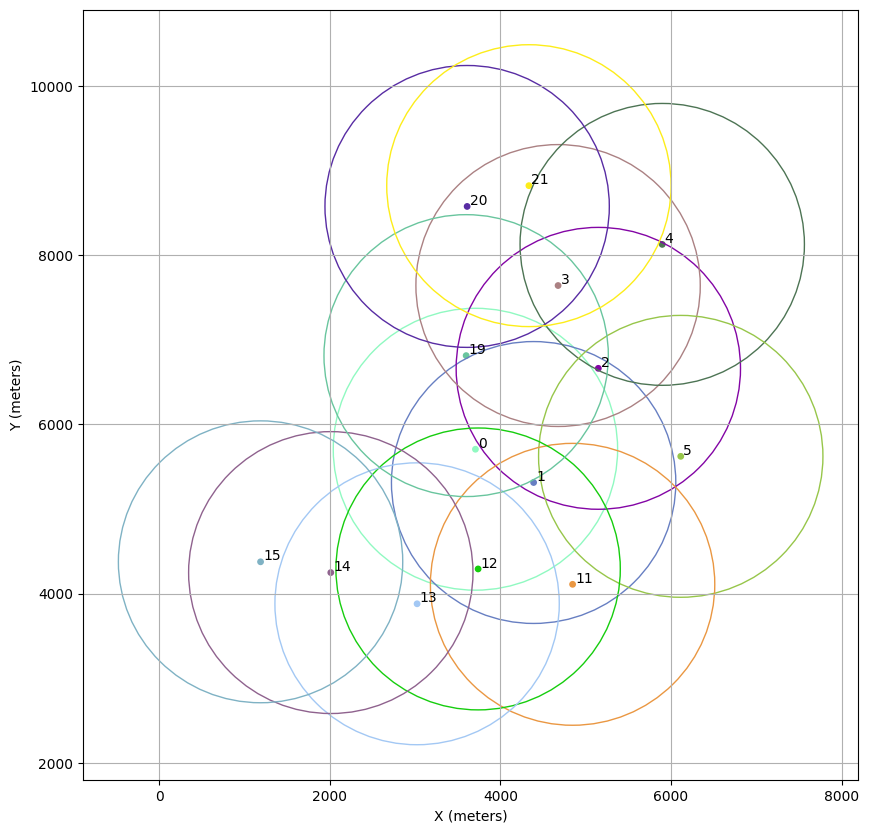

In [33]:
fig, ax = plt.subplots()

rand_color_1 = np.random.rand(len(df_updated), 3)
fig.set_size_inches(10, 10)
ax.scatter(df_updated['X_coord'], df_updated['Y_coord'], s=15, c=rand_color_1)


ax.set_xlabel('X (meters)')
ax.set_ylabel('Y (meters)')
plt.grid(True)
j = 0


for i in index:
  plt.annotate(i, (df_updated['X_coord'][i] + 30, df_updated['Y_coord'][i] + 20))
  circle = plt.Circle((df_updated['X_coord'][i], df_updated['Y_coord'][i]), R, color=rand_color_1[j], fill=False)
  ax.add_patch(circle)
  j += 1

plt.show()

In [34]:
def distance(A, B):
  return np.sqrt((df['X_coord'][A] - df['X_coord'][B])**2 + (df['Y_coord'][A] - df['Y_coord'][B])**2)

In [35]:
points = df[['X_coord', 'Y_coord']]

Calcoliamo quindi la copertura per ogni pizzeria, verifichiamo quindi quali sono gli utenti che possiamo andare a servire per ogni singola pizzeria considerando il raggio calcolato

In [36]:
coverage = []

for i in index:
  covered = []
  for j in index:
    if distance(i, j) <= R:
      covered.append(j)
  coverage.append(covered)

In [37]:
coverage

[[0, 1, 12, 19],
 [0, 1, 2, 11, 12],
 [1, 2, 3, 4, 5, 19],
 [2, 3, 4, 19, 20, 21],
 [2, 3, 4],
 [2, 5],
 [1, 11, 12],
 [0, 1, 11, 12, 13],
 [12, 13, 14],
 [13, 14, 15],
 [14, 15],
 [0, 2, 3, 19],
 [3, 20, 21],
 [3, 20, 21]]

In [38]:
coverage = [set(lst) for lst in coverage]
solutions = []

for r in range(len(coverage)):
  for comb in combinations(range(len(coverage)), r):
    union = set().union(*[coverage[i] for i in comb])
    if union == set(index.tolist()):
      solutions.append(comb)

In [39]:
solutions

[(1, 2, 3, 9),
 (1, 2, 9, 12),
 (1, 2, 9, 13),
 (1, 3, 5, 9),
 (2, 3, 7, 9),
 (2, 3, 7, 10),
 (2, 7, 9, 12),
 (2, 7, 9, 13),
 (2, 7, 10, 12),
 (2, 7, 10, 13),
 (3, 5, 7, 9),
 (3, 5, 7, 10),
 (0, 1, 2, 3, 9),
 (0, 1, 2, 9, 12),
 (0, 1, 2, 9, 13),
 (0, 1, 3, 5, 9),
 (0, 2, 3, 6, 9),
 (0, 2, 3, 7, 9),
 (0, 2, 3, 7, 10),
 (0, 2, 6, 9, 12),
 (0, 2, 6, 9, 13),
 (0, 2, 7, 9, 12),
 (0, 2, 7, 9, 13),
 (0, 2, 7, 10, 12),
 (0, 2, 7, 10, 13),
 (0, 3, 5, 6, 9),
 (0, 3, 5, 7, 9),
 (0, 3, 5, 7, 10),
 (1, 2, 3, 4, 9),
 (1, 2, 3, 5, 9),
 (1, 2, 3, 6, 9),
 (1, 2, 3, 7, 9),
 (1, 2, 3, 7, 10),
 (1, 2, 3, 8, 9),
 (1, 2, 3, 8, 10),
 (1, 2, 3, 9, 10),
 (1, 2, 3, 9, 11),
 (1, 2, 3, 9, 12),
 (1, 2, 3, 9, 13),
 (1, 2, 4, 9, 12),
 (1, 2, 4, 9, 13),
 (1, 2, 5, 9, 12),
 (1, 2, 5, 9, 13),
 (1, 2, 6, 9, 12),
 (1, 2, 6, 9, 13),
 (1, 2, 7, 9, 12),
 (1, 2, 7, 9, 13),
 (1, 2, 7, 10, 12),
 (1, 2, 7, 10, 13),
 (1, 2, 8, 9, 12),
 (1, 2, 8, 9, 13),
 (1, 2, 8, 10, 12),
 (1, 2, 8, 10, 13),
 (1, 2, 9, 10, 12),
 (1, 2, 9, 10, 1

Ora che abbiamo trovato tutte le soluzioni che vanno bene andiamo a scegliere quella che minimizza il costo totale di affitto

In [42]:
best_solution_updated = []
min_value = float('inf')

for solution in solutions:
  total_cost = 0
  for i in solution:
      total_cost += df['Costo affitto'][index[i]]
  if total_cost < min_value:
    min_value = total_cost
    best_solution_updated = solution

In [43]:
print(best_solution_updated)

(3, 5, 6, 9, 11)


Aggiorniamo quindi la soluzione ricordando che il valore che troviamo effettivamente in ordine nel dataframe non è quello degli indici di partenza

In [44]:
best_solution = []
for i in best_solution_updated:
  best_solution.append(index[i])

In [45]:
print(best_solution)

[np.int64(3), np.int64(5), np.int64(11), np.int64(14), np.int64(19)]


Aggiungiamo tutte le pizzerie che abbiamo rimosso precedentemente e le ordiniamo per comodità

In [46]:
best_solution = list(best_solution)
best_solution.extend(pizzerias)
best_solution.extend(pizzerias_1)
best_solution = np.sort(best_solution)

In [47]:
best_solution = best_solution.astype(int)

In [48]:
print("I migliori quartieri in cui aprire le pizzerie per minimizzare l'affitto sono:")
sum = 0
for i in best_solution:
  print(df['Quartieri'][i], int(i) + 1)
  sum += df['Costo affitto'][i]
print("Con costo minimizzato pari a: %2d" %sum)

I migliori quartieri in cui aprire le pizzerie per minimizzare l'affitto sono:
Saviabona 4
San Pio X 6
Bertesina 7
Bertesinella 8
San Pietro Intrigogna 10
Riviera Berica 11
Campedello 12
Ferrovieri 15
Villaggio del sole Pomari 17
Maddalene 19
San Bortolo 20
Con costo minimizzato pari a: 6600


# Problema risolto ✅

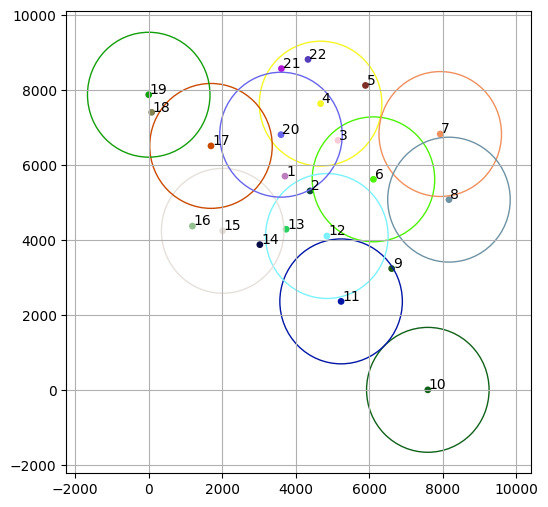

In [49]:
fig, ax = plt.subplots()

fig.set_size_inches(6, 6)
ax.scatter(df['X_coord'], df['Y_coord'], s=15, c=rand_color)


#ax.set_xlabel('X (meters)')
#ax.set_ylabel('Y (meters)')
plt.grid(True)
j = 0

for i in df.index:
  plt.annotate(i + 1, (df['X_coord'][i] + 30, df['Y_coord'][i] + 20))

for i in best_solution:
  circle = plt.Circle((df['X_coord'][i], df['Y_coord'][i]), R, color=rand_color[i], fill=False)
  ax.add_patch(circle)

plt.show()

Calcoliamo la matrice delle distanze che adopererò anche per risolvere più efficientemente con il risolutore lineare del simplesso

In [50]:
matrix = np.zeros(shape=(len(df), len(df)))

for i in range(len(df)):
  for j in range(len(df)):
    if (distance(i, j) <= R): matrix[i][j] = 1
    else: matrix[i][j] = 0

In [51]:
pd.DataFrame(matrix, dtype=int).to_csv('matrix.csv')